# **Homework 11 - Unsupervised Learning**

**Context:**

In Chapter 7 of Dive into Data Science, this chapter uses probability distributions, simulations, and clustering techniques to demonstrate how observations can be grouped based on their similarities. Through these activities, I explored how machine learning algorithms can identify structure within data automatically.

**Problem/Purpse:**

The purpose of this lab is to understand how unsupervised learning methods organize data into meaningful groups. I will analyze simulated dice roll data, compare probability distributions, and use clustering algorithms to identify patterns within a dataset. This will help demonstrate how data can be classified and grouped when the correct answers are not already known.

**Arroach/Solution:**

First, we simulate multiple dice rolls and study the distribution of their sums using histograms and statistical measurements such as the mean and standard deviation. Then we compare these distributions to normal distributions and examine probability density values for different observations.

the next step is to combine multiple datasets and use probability-based classification techniques to determine which distribution specific observations most likely belong to. Finally, apply clustering methods, including an iterative clustering process and the K-Means algorithm, to group observations within a two-dimensional dataset and compare the resulting cluster centers.

In [1]:
from random import choices, seed
import numpy as np
from matplotlib import pyplot as plt
import scipy.stats as stats
import math

numberofrolls = 1800

seed(9)

dice1 = choices([1, 2, 3, 4, 5, 6], k=numberofrolls)
dice2 = choices([1, 2, 3, 4, 5, 6], k=numberofrolls)

print("First 10 Rolls of Dice 1:")
print(dice1[0:10])

print("\nFirst 10 Rolls of Dice 2:")
print(dice2[0:10])


First 10 Rolls of Dice 1:
[3, 3, 1, 6, 1, 4, 6, 1, 4, 4]

First 10 Rolls of Dice 2:
[5, 2, 5, 5, 3, 2, 3, 5, 4, 2]


In [2]:
dicesum = [
    dice1[n] + dice2[n]
    for n in range(numberofrolls)
]

print("First 10 Dice Sums:")
print(dicesum[0:10])

print("\nTotal Number of Rolls:")
print(len(dicesum))


First 10 Dice Sums:
[8, 5, 6, 11, 4, 6, 9, 6, 8, 6]

Total Number of Rolls:
1800


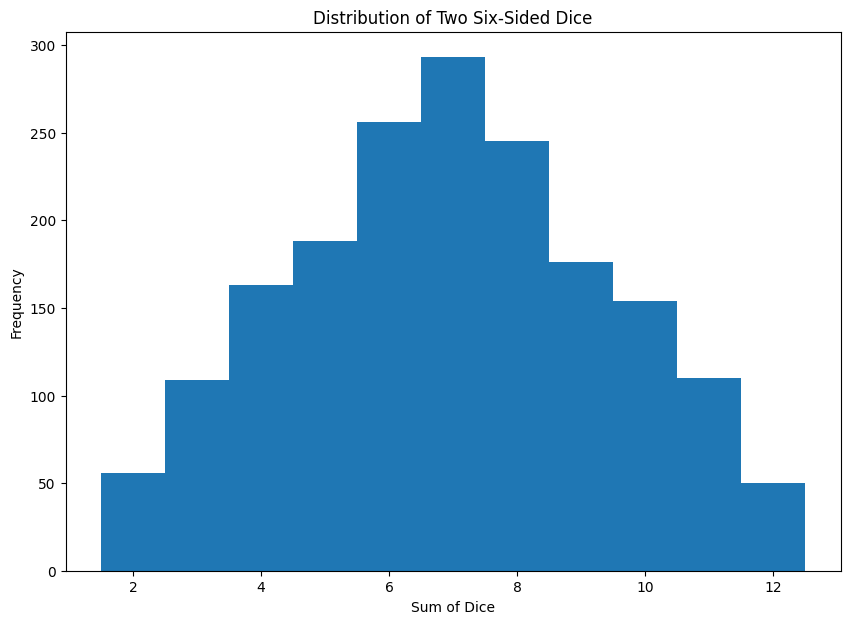

In [3]:

fig, ax = plt.subplots(figsize=(10, 7))

ax.hist(
    dicesum,
    bins=[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
    align='left'
)

plt.title('Distribution of Two Six-Sided Dice')
plt.xlabel('Sum of Dice')
plt.ylabel('Frequency')

plt.show()


In [4]:

def getcenter(allpoints):
    center = np.mean(allpoints)
    stdev = np.sqrt(np.cov(allpoints))
    return (center, stdev)

print("Mean and Standard Deviation:")
print(getcenter(dicesum))


Mean and Standard Deviation:
(np.float64(6.9511111111111115), np.float64(2.468219092930105))


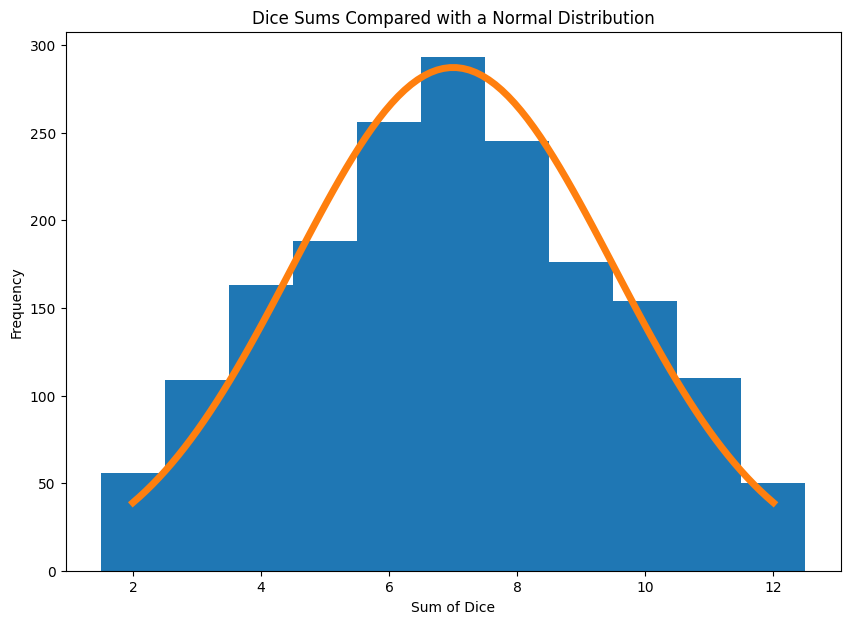

In [5]:

fig, ax = plt.subplots(figsize=(10, 7))

ax.hist(
    dicesum,
    bins=range(2, 14),
    align='left'
)

mu = 7
sigma = 2.5

x = np.linspace(
    mu - 2*sigma,
    mu + 2*sigma,
    100
)

plt.plot(
    x,
    stats.norm.pdf(x, mu, sigma) * numberofrolls,
    linewidth=5
)

plt.title('Dice Sums Compared with a Normal Distribution')
plt.xlabel('Sum of Dice')
plt.ylabel('Frequency')

plt.show()


In [6]:

print("Value at 2:")
print(stats.norm.pdf(2, mu, sigma) * numberofrolls)

print("\nValue at 7:")
print(stats.norm.pdf(7, mu, sigma) * numberofrolls)

print("\nValue at 12:")
print(stats.norm.pdf(12, mu, sigma) * numberofrolls)


Value at 2:
38.8734958894954

Value at 7:
287.23844188903155

Value at 12:
38.8734958894954


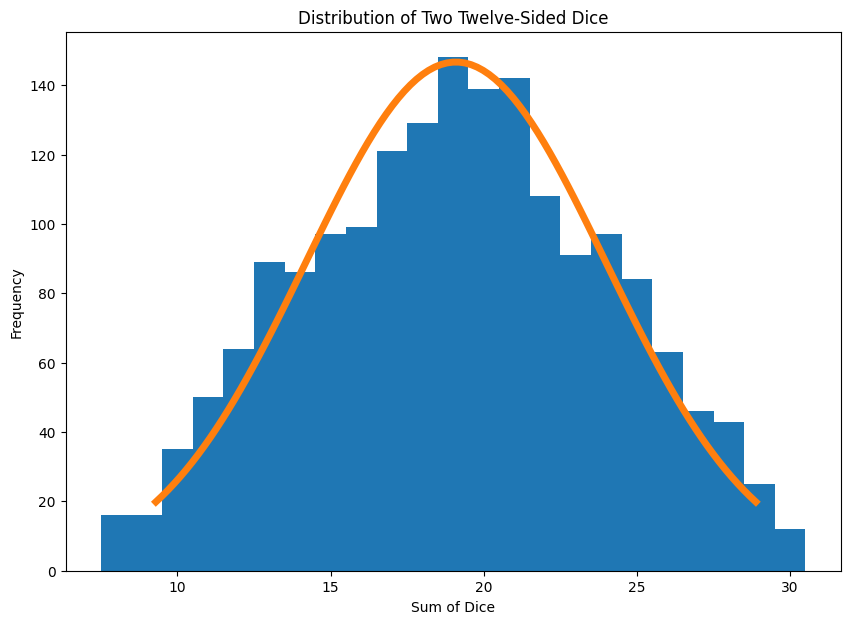

In [7]:

seed(913)

dice1 = choices(
    [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
    k=numberofrolls
)

dice2 = choices(
    [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
    k=numberofrolls
)

dicesum12 = [
    dice1[n] + dice2[n]
    for n in range(numberofrolls)
]

fig, ax = plt.subplots(figsize=(10, 7))

ax.hist(
    dicesum12,
    bins=range(8, 32),
    align='left'
)

mu = np.mean(dicesum12)
sigma = np.std(dicesum12)

x = np.linspace(
    mu - 2*sigma,
    mu + 2*sigma,
    100
)

plt.plot(
    x,
    stats.norm.pdf(x, mu, sigma) * numberofrolls,
    linewidth=5
)

plt.title('Distribution of Two Twelve-Sided Dice')
plt.xlabel('Sum of Dice')
plt.ylabel('Frequency')

plt.show()


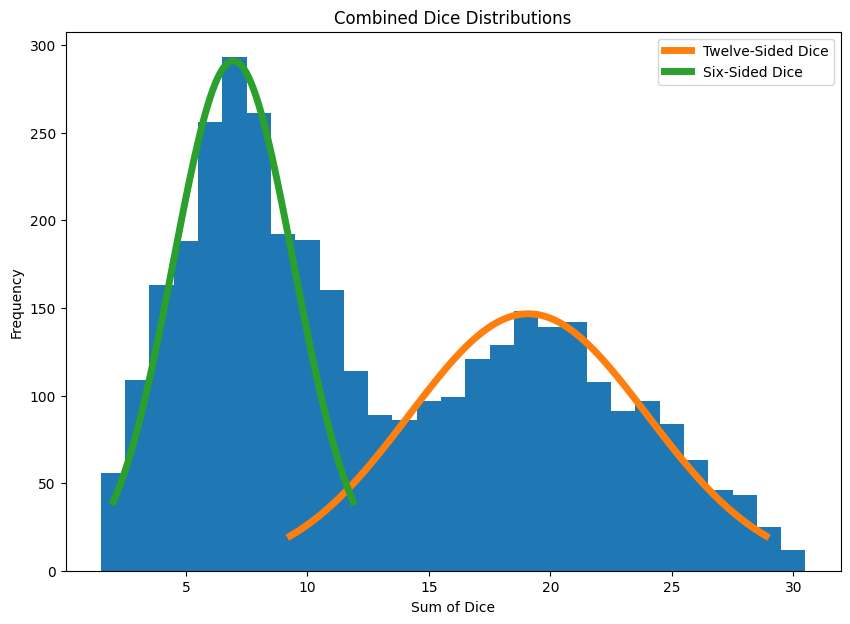

In [8]:

dicesumboth = dicesum + dicesum12

fig, ax = plt.subplots(figsize=(10, 7))

ax.hist(
    dicesumboth,
    bins=range(2, 32),
    align='left'
)

mu = np.mean(dicesum12)
sigma = np.std(dicesum12)

x = np.linspace(mu - 2*sigma, mu + 2*sigma, 100)

plt.plot(
    x,
    stats.norm.pdf(x, mu, sigma) * numberofrolls,
    linewidth=5,
    label='Twelve-Sided Dice'
)

mu = np.mean(dicesum)
sigma = np.std(dicesum)

x = np.linspace(mu - 2*sigma, mu + 2*sigma, 100)

plt.plot(
    x,
    stats.norm.pdf(x, mu, sigma) * numberofrolls,
    linewidth=5,
    label='Six-Sided Dice'
)

plt.title('Combined Dice Distributions')
plt.xlabel('Sum of Dice')
plt.ylabel('Frequency')
plt.legend()

plt.show()


In [9]:

seed(494)

randomselection = choices(dicesumboth, k=1)

print("Randomly Selected Observation:")
print(randomselection)


Randomly Selected Observation:
[12]


In [10]:

print("Probability Density Comparison for Value 8:")

print("Six-Sided Dice:")
print(
    stats.norm.pdf(
        8,
        np.mean(dicesum),
        np.std(dicesum)
    ) * numberofrolls
)

print("\nTwelve-Sided Dice:")
print(
    stats.norm.pdf(
        8,
        np.mean(dicesum12),
        np.std(dicesum12)
    ) * numberofrolls
)


Probability Density Comparison for Value 8:
Six-Sided Dice:
265.87855493973007

Twelve-Sided Dice:
11.289203035758725


In [11]:

print("Probability Density Comparison for Value 12:")

print("Six-Sided Dice:")
print(
    stats.norm.pdf(
        12,
        np.mean(dicesum),
        np.std(dicesum)
    ) * numberofrolls
)

print("\nTwelve-Sided Dice:")
print(
    stats.norm.pdf(
        12,
        np.mean(dicesum12),
        np.std(dicesum12)
    ) * numberofrolls
)


Probability Density Comparison for Value 12:
Six-Sided Dice:
35.87586208537935

Twelve-Sided Dice:
51.42993240324318


In [12]:

from scipy.stats import multivariate_normal

def classify(allpts, allmns, allvar):
    vars = []

    for n in range(len(allmns)):
        vars.append(
            multivariate_normal(
                mean=allmns[n],
                cov=allvar[n]
            )
        )

    classification = []

    for point in allpts:
        this_classification = -1
        this_pdf = 0

        for n in range(len(allmns)):
            if vars[n].pdf(point) > this_pdf:
                this_pdf = vars[n].pdf(point)
                this_classification = n + 1

        classification.append(this_classification)

    return classification


In [13]:

allpoints = [2, 8, 12, 15, 25]

allmeans = [7, 19]

allvar = [
    np.cov(dicesum),
    np.cov(dicesum12)
]

print("Classification Results:")
print(classify(allpoints, allmeans, allvar))


Classification Results:
[1, 1, 2, 2, 2]


In [14]:

import ast
import requests

link = "https://bradfordtuckfield.com/emdata.txt"

f = requests.get(link, timeout=30)
f.raise_for_status()

allpoints = ast.literal_eval(f.text)

print("Dataset Loaded Successfully")
print("Number of Points:", len(allpoints))

print("\nFirst 10 Points:")
print(allpoints[:10])


Dataset Loaded Successfully
Number of Points: 1800

First 10 Points:
[(-0.1552675464942554, -0.09969103286971781), (-0.43451816054370895, -0.2843645740995829), (-0.3014078398152444, 0.17346914107296707), (-0.30301227549315163, -0.0565929491122545), (-0.29479812816166023, 0.4324337507373298), (-0.5564405785917151, -0.9207197704818232), (0.3199678679968572, -0.09204172954419705), (0.30267335116362837, 0.1358617853586582), (-0.37164058764887664, 0.35462437600634317), (-0.2965188528249831, 0.483555020257342)]


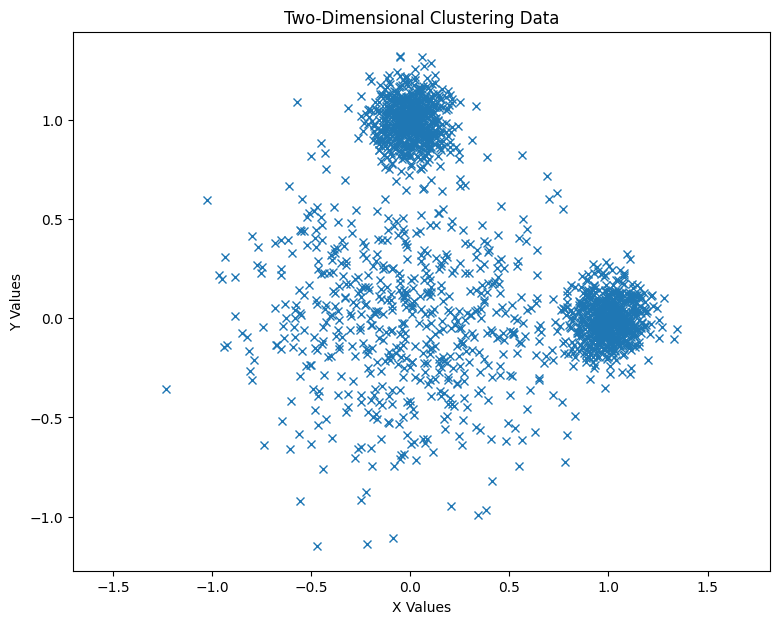

In [15]:

allxs = [point[0] for point in allpoints]
allys = [point[1] for point in allpoints]

plt.figure(figsize=(9, 7))

plt.plot(allxs, allys, 'x')

plt.title('Two-Dimensional Clustering Data')
plt.xlabel('X Values')
plt.ylabel('Y Values')

plt.axis('equal')
plt.show()


In [16]:

mean1 = [-1, 0]
mean2 = [0.5, -1]
mean3 = [0.5, 0.5]

allmeans = [
    mean1,
    mean2,
    mean3
]

cov1 = [[1, 0], [0, 1]]
cov2 = [[1, 0], [0, 1]]
cov3 = [[1, 0], [0, 1]]

allvar = [
    cov1,
    cov2,
    cov3
]

print("Initial Cluster Centers:")
print(allmeans)


Initial Cluster Centers:
[[-1, 0], [0.5, -1], [0.5, 0.5]]


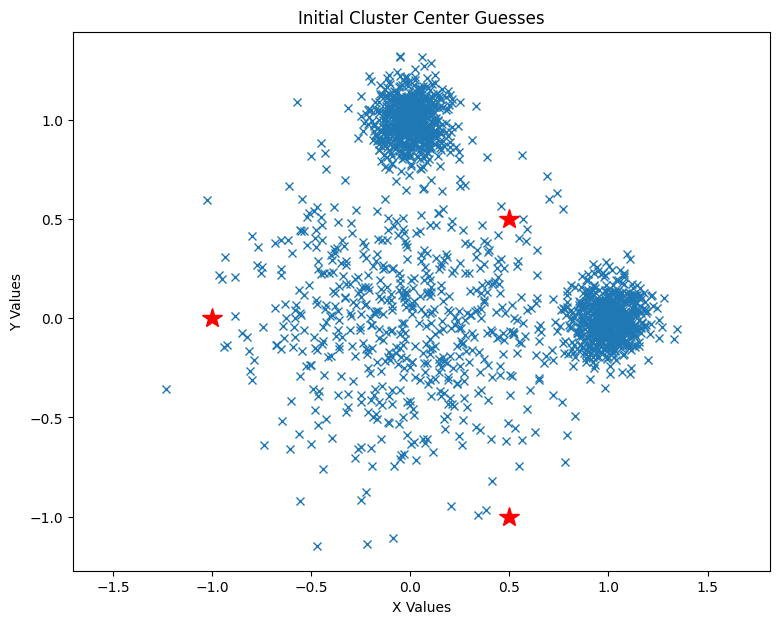

In [17]:

plt.figure(figsize=(9, 7))

plt.plot(allxs, allys, 'x')

plt.plot(mean1[0], mean1[1], 'r*', markersize=15)
plt.plot(mean2[0], mean2[1], 'r*', markersize=15)
plt.plot(mean3[0], mean3[1], 'r*', markersize=15)

plt.title('Initial Cluster Center Guesses')
plt.xlabel('X Values')
plt.ylabel('Y Values')

plt.axis('equal')
plt.show()


In [18]:

theclass = classify(
    allpoints,
    allmeans,
    allvar
)

print("First 10 Cluster Assignments:")
print(theclass[:10])

print("\nNumber of Classified Points:")
print(len(theclass))


First 10 Cluster Assignments:
[1, 1, 1, 1, 3, 1, 3, 3, 1, 3]

Number of Classified Points:
1800


In [19]:

def makeplot(allpoints, theclass, allmeans):
    thecolors = ['black'] * len(allpoints)

    for idx in range(len(thecolors)):
        if theclass[idx] == 2:
            thecolors[idx] = 'green'

        if theclass[idx] == 3:
            thecolors[idx] = 'yellow'

    allxs = [point[0] for point in allpoints]
    allys = [point[1] for point in allpoints]

    plt.figure(figsize=(9, 7))

    for i in range(len(allpoints)):
        plt.scatter(
            allxs[i],
            allys[i],
            color=thecolors[i]
        )

    for i in range(len(allmeans)):
        plt.plot(
            allmeans[i][0],
            allmeans[i][1],
            'b*',
            markersize=15
        )

    plt.title('Cluster Assignments')
    plt.xlabel('X Values')
    plt.ylabel('Y Values')

    plt.axis('equal')
    plt.show()


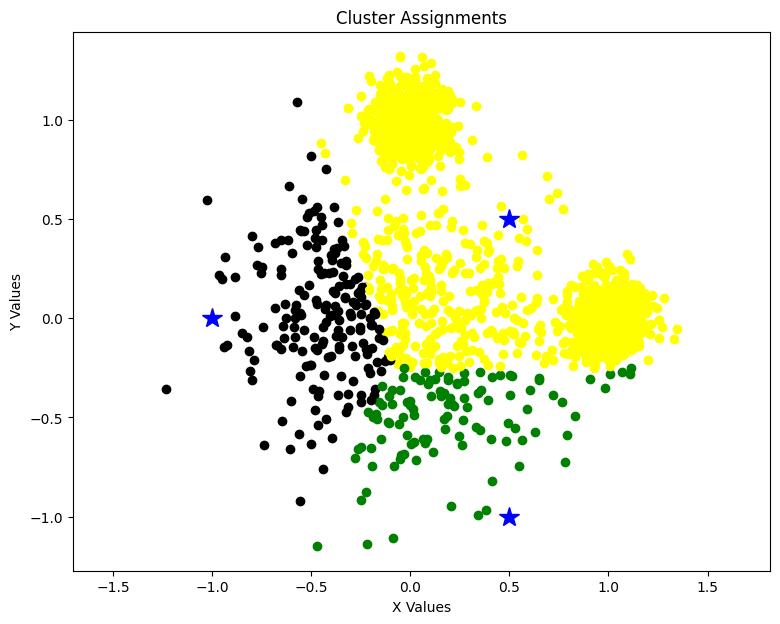

In [ ]:

makeplot(
    allpoints,
    theclass,
    allmeans
)


In [20]:

def getcenters(allpoints, theclass, k):
    centers = []
    thevars = []

    for n in range(k):
        pointsn = [
            allpoints[i]
            for i in range(len(allpoints))
            if theclass[i] == (n + 1)
        ]

        xpointsn = [point[0] for point in pointsn]
        ypointsn = [point[1] for point in pointsn]

        xcenter = np.mean(xpointsn)
        ycenter = np.mean(ypointsn)

        centers.append([xcenter, ycenter])

        thevars.append(
            np.cov(xpointsn, ypointsn)
        )

    return centers, thevars


Updated Cluster Centers:
[[np.float64(-0.45837983551892464), np.float64(0.01812933980535851)], [np.float64(0.2078346537487099), np.float64(-0.5028394290721085)], [np.float64(0.4376771212802838), np.float64(0.43019895678076053)]]


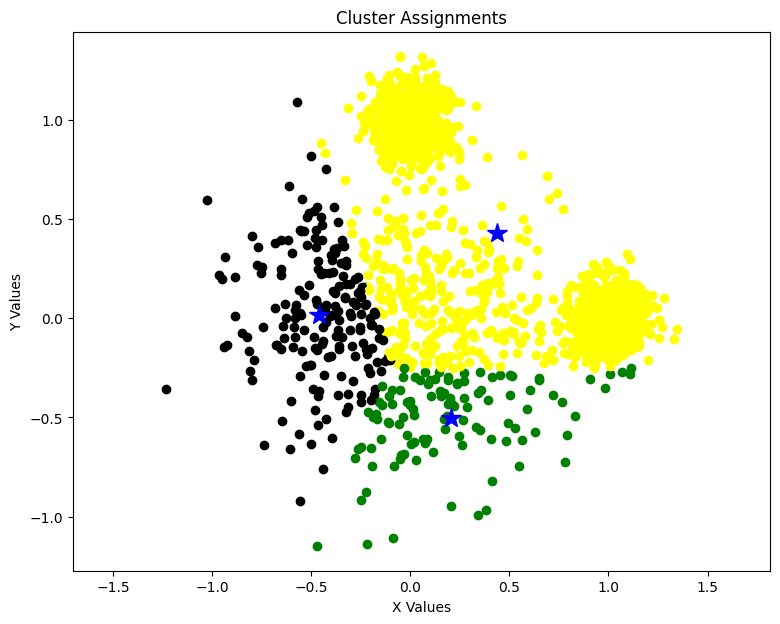

In [21]:

allmeans, allvar = getcenters(
    allpoints,
    theclass,
    3
)

print("Updated Cluster Centers:")
print(allmeans)

makeplot(
    allpoints,
    theclass,
    allmeans
)


Updated Cluster Assignments:
[1, 1, 1, 1, 1, 2, 2, 3, 1, 1]


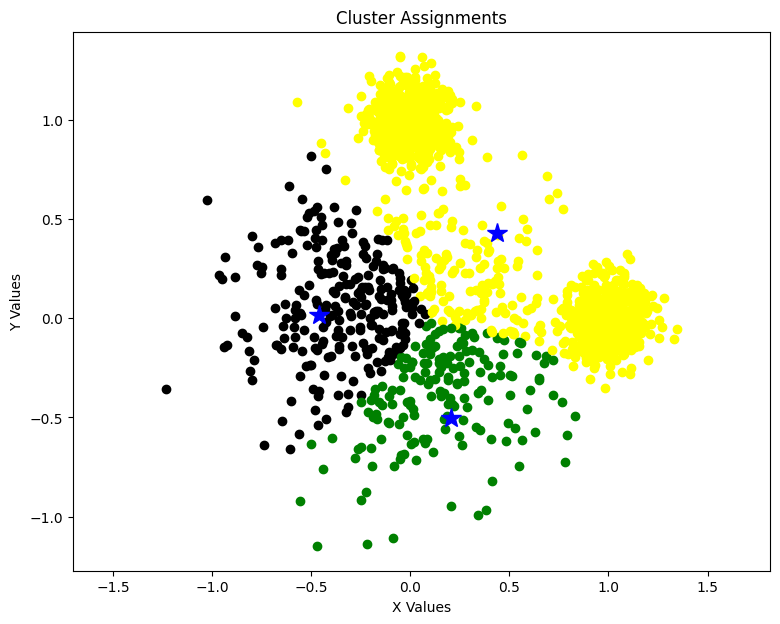

In [22]:

theclass = classify(
    allpoints,
    allmeans,
    allvar
)

print("Updated Cluster Assignments:")
print(theclass[:10])

makeplot(
    allpoints,
    theclass,
    allmeans
)


In [23]:

for n in range(0, 100):
    theclass = classify(
        allpoints,
        allmeans,
        allvar
    )

    allmeans, allvar = getcenters(
        allpoints,
        theclass,
        3
    )

print("Clustering Iterations Complete")

print("\nFinal Cluster Centers:")
print(allmeans)

print("\nFirst 10 Final Cluster Assignments:")
print(theclass[:10])


Clustering Iterations Complete

Final Cluster Centers:
[[np.float64(-0.027929414489597838), np.float64(-0.018295684369046116)], [np.float64(1.0007942750468535), np.float64(-0.005810306838373317)], [np.float64(0.002170758845744432), np.float64(0.9955538478549281)]]

First 10 Final Cluster Assignments:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


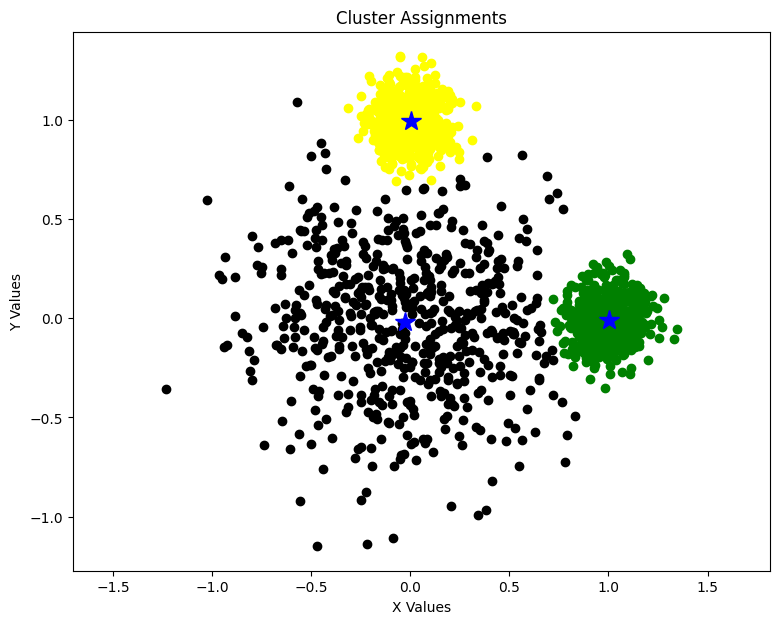

In [24]:

makeplot(
    allpoints,
    theclass,
    allmeans
)


In [25]:

from sklearn.cluster import KMeans

kmeans = KMeans(
    init="random",
    n_clusters=3,
    n_init=10,
    max_iter=300,
    random_state=42
)

kmeans.fit(allpoints)

newclass = [
    label + 1
    for label in kmeans.labels_
]

print("K-Means Cluster Centers:")
print(kmeans.cluster_centers_)

print("\nFirst 10 K-Means Assignments:")
print(newclass[:10])


K-Means Cluster Centers:
[[-0.00449803  0.96730577]
 [ 0.94948593 -0.00946174]
 [-0.12510149 -0.07923161]]

First 10 K-Means Assignments:
[np.int32(3), np.int32(3), np.int32(3), np.int32(3), np.int32(3), np.int32(3), np.int32(3), np.int32(3), np.int32(3), np.int32(1)]


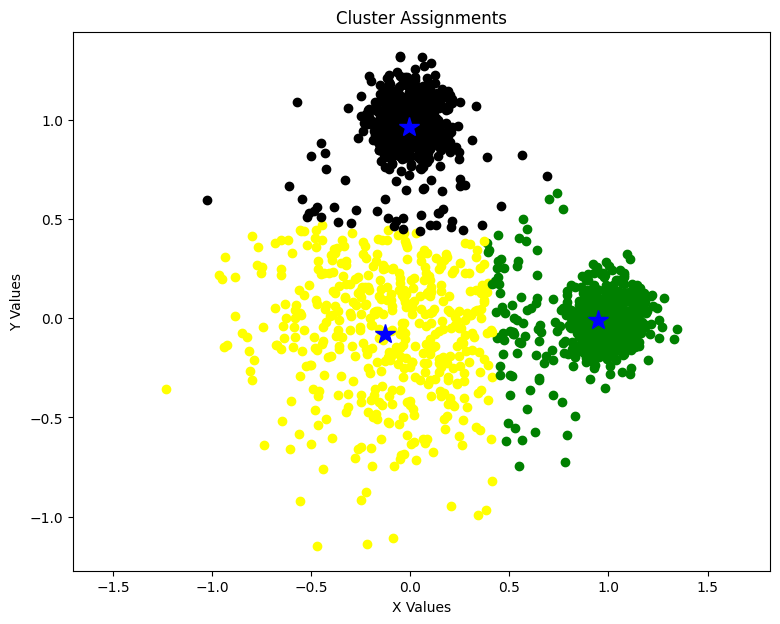

In [26]:

makeplot(
    allpoints,
    newclass,
    kmeans.cluster_centers_
)


In [27]:

print("Probability-Based Clustering Centers:")

for i, center in enumerate(allmeans):
    print("Cluster", i + 1, ":", center)

print("\nK-Means Clustering Centers:")

for i, center in enumerate(kmeans.cluster_centers_):
    print("Cluster", i + 1, ":", center)

print("\nNumber of Points in Each K-Means Cluster:")

unique, counts = np.unique(newclass, return_counts=True)

for cluster, count in zip(unique, counts):
    print("Cluster", cluster, ":", count, "points")


Probability-Based Clustering Centers:
Cluster 1 : [np.float64(-0.027929414489597838), np.float64(-0.018295684369046116)]
Cluster 2 : [np.float64(1.0007942750468535), np.float64(-0.005810306838373317)]
Cluster 3 : [np.float64(0.002170758845744432), np.float64(0.9955538478549281)]

K-Means Clustering Centers:
Cluster 1 : [-0.00449803  0.96730577]
Cluster 2 : [ 0.94948593 -0.00946174]
Cluster 3 : [-0.12510149 -0.07923161]

Number of Points in Each K-Means Cluster:
Cluster 1 : 658 points
Cluster 2 : 690 points
Cluster 3 : 452 points


In [28]:
print("Chapter 7 Verification")

print("\nChecking Dice Simulations:")
print("Six-Sided Dice Rolls:", len(dicesum))
print("Twelve-Sided Dice Rolls:", len(dicesum12))
print("Combined Observations:", len(dicesumboth))

assert len(dicesum) == 1800
assert len(dicesum12) == 1800
assert len(dicesumboth) == 3600

print("\nChecking Clustering Dataset:")
print("Total Data Points:", len(allpoints))
print("Probability-Based Assignments:", len(theclass))
print("K-Means Assignments:", len(newclass))

assert len(allpoints) == len(theclass)
assert len(allpoints) == len(newclass)

print("\nChecking K-Means Clusters:")
print("Number of Clusters:", kmeans.n_clusters)

assert kmeans.n_clusters == 3

print("\nChecking Cluster Labels:")

valid_labels = all(
    label in [1, 2, 3]
    for label in newclass
)

print("All Labels Valid:", valid_labels)

assert valid_labels
assert set(newclass) == {1, 2, 3}

print("\nChecking Cluster Centers:")

assert np.isfinite(np.array(allmeans)).all()
assert np.isfinite(kmeans.cluster_centers_).all()

print("All Cluster Centers Are Finite")

print("\nVerification Complete!")


Chapter 7 Verification

Checking Dice Simulations:
Six-Sided Dice Rolls: 1800
Twelve-Sided Dice Rolls: 1800
Combined Observations: 3600

Checking Clustering Dataset:
Total Data Points: 1800
Probability-Based Assignments: 1800
K-Means Assignments: 1800

Checking K-Means Clusters:
Number of Clusters: 3

Checking Cluster Labels:
All Labels Valid: True

Checking Cluster Centers:
All Cluster Centers Are Finite

Verification Complete!


**Results/Observations:**

The dice simulations produced distributions that followed the expected patterns, with values near the center occurring more frequently than values near the extremes. The clustering algorithms successfully separated the dataset into three distinct groups. Both the probability-based clustering method and K-Means identified similar cluster locations, demonstrating that unsupervised learning techniques can effectively discover patterns in data without labeled examples.

**Conclusion:**

This lab provided experience with probability distributions, classification, and clustering techniques used in unsupervised learning. By working through simulations and clustering examples, I gained a better understanding of how machine learning algorithms can identify relationships and organize data into meaningful groups. These concepts are important because they allow useful information to be extracted from data even when the correct classifications are unknown.

**Verification:**

The code executed successfully in Google Colab and produced the expected visualizations, statistical calculations, and clustering results. The verification checks confirmed that the datasets contained the correct number of observations and that all clustering methods generated valid outputs.